Breve explicación de las modificaciones y reutilización del código (Tarea 2 
→
→
 Tarea 3)
Conservación del núcleo del SGA (Tarea 2): Se mantuvieron las mismas librerías (math, random, numpy, matplotlib.pyplot), la estructura de generación de cromosomas binarios, los operadores genéticos (cruce_un_punto, mutacion) y tu función original seleccion_ruleta(poblacion, fitness_poblacion).
Adaptación de la Población Inicial y Fitness (Requisito Tarea 3): Se adaptó inicializar_poblacion_t3() para generar los individuos junto con una función de adaptación (fitness) compuesta por números enteros aleatorios entre 1 y 1000, tal como lo exige el documento de la Tarea 3.
Estandarización de los Operadores de Selección:
Mientras que la ruleta simple selecciona 1 padre a la vez, métodos como Universal Estocástica (SUS), Sobrante Estocástico y Muestreo Determinístico calculan los valores esperados (
e
i
=
N
⋅
p
i
e 
i
​
 =N⋅p 
i
​
 
) para seleccionar toda la población de 
N
N
 padres simultáneamente.
Por ello, se conservó tu función seleccion_ruleta intacta y se crearon funciones modulares para las 8 variantes solicitadas que retornan tanto los 
N
N
 padres seleccionados como el conteo exacto de cuántas veces fue elegido cada individuo para facilitar el análisis estadístico y gráfico.

# **Librerias y funciones matematicas**

In [19]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt

# Semilla opcional para reproducibilidad en las pruebas comparativas
random.seed(42)
np.random.seed(42)

def inicializar_poblacion_t3(n_poblacion, longitud_cromosoma=10):
    """
    Reutiliza la logica de generacion de cromosomas de la Tarea 2,
    asignando una funcion de adaptacion (fitness) con numeros enteros entre 1 y 1000.
    """
    poblacion = []
    fitness_poblacion = []

    for i in range(n_poblacion):
        cromosoma = [random.randint(0, 1) for _ in range(longitud_cromosoma)]
        poblacion.append(cromosoma)
        # Requisito Tarea 3: Funcion de adaptacion entera entre 1 y 1000
        fitness_ind = random.randint(1, 1000)
        fitness_poblacion.append(fitness_ind)

    return poblacion, fitness_poblacion

# Operadores de Cruce y Mutacion (Reutilizados integramente de la Tarea 2)
def cruce_un_punto(padre1, padre2, prob_cruce):
    if random.random() < prob_cruce:
        punto_corte = random.randint(1, len(padre1) - 1)
        hijo1 = padre1[:punto_corte] + padre2[punto_corte:]
        hijo2 = padre2[:punto_corte] + padre1[:punto_corte]
    else:
        hijo1 = padre1[:]
        hijo2 = padre2[:]
    return hijo1, hijo2

def mutacion(cromosoma, prob_mutacion):
    for i in range(len(cromosoma)):
        if random.random() < prob_mutacion:
            cromosoma[i] = 1 - cromosoma[i]
    return cromosoma

In [20]:
# ==============================================================================
# 1.1 RULETA (Conservada de la Tarea 2 + Envolvente para N padres)
# ==============================================================================
def seleccion_ruleta_individuo(poblacion, fitness_poblacion):
    """Funcion original de la Tarea 2 (retorna el indice y el individuo ganador)"""
    suma_total_fitness = sum(fitness_poblacion)
    r = random.uniform(0, suma_total_fitness)

    suma_acumulada = 0
    for i in range(len(poblacion)):
        suma_acumulada += fitness_poblacion[i]
        if suma_acumulada >= r:
            return i, poblacion[i]
    return len(poblacion) - 1, poblacion[-1]

def seleccion_ruleta(poblacion, fitness_poblacion):
    """Gira la ruleta N veces para seleccionar la poblacion de padres"""
    n = len(poblacion)
    padres = []
    conteo_seleccion = [0] * n

    for _ in range(n):
        idx, padre = seleccion_ruleta_individuo(poblacion, fitness_poblacion)
        padres.append(padre[:])
        conteo_seleccion[idx] += 1

    return padres, conteo_seleccion


# ==============================================================================
# 1.2 SOBRANTE ESTOCASTICO CON REEMPLAZO (SP)
# ==============================================================================
def seleccion_sobrante_con_reemplazo(poblacion, fitness_poblacion):
    """
    Asigna copias segun la parte entera del valor esperado (e_i).
    Los cupos faltantes se eligen usando una Ruleta sobre las partes fraccionarias.
    """
    n = len(poblacion)
    suma_total_fitness = sum(fitness_poblacion)
    
    padres = []
    conteo_seleccion = [0] * n
    partes_fraccionarias = []

    # 1.Calculo de valores esperados e_i y asignacion de partes enteras
    for i in range(n):
        valor_esperado = (fitness_poblacion[i] / suma_total_fitness) * n
        parte_entera = int(math.floor(valor_esperado))
        parte_frac = valor_esperado - parte_entera

        partes_fraccionarias.append(parte_frac)
        conteo_seleccion[i] += parte_entera
        for _ in range(parte_entera):
            padres.append(poblacion[i][:])

    # 2. Completar los padres faltantes girando una ruleta con las partes fraccionarias
    faltantes = n - len(padres)
    for _ in range(faltantes):
        idx, padre = seleccion_ruleta_individuo(poblacion, partes_fraccionarias)
        padres.append(padre[:])
        conteo_seleccion[idx] += 1

    return padres, conteo_seleccion


# ==============================================================================
# 1.3 SOBRANTE ESTOCASTICO SIN REEMPLAZO (SP)
# ==============================================================================
def seleccion_sobrante_sin_reemplazo(poblacion, fitness_poblacion):
    """
    Asigna copias segun la parte entera del valor esperado (e_i).
    Los cupos faltantes se eligen mediante pruebas de Bernoulli (moneda cargada)
    usando la parte fraccionaria como probabilidad, sin reemplazo.
    """
    n = len(poblacion)
    suma_total_fitness = sum(fitness_poblacion)
    
    padres = []
    conteo_seleccion = [0] * n
    partes_fraccionarias = []

    # 1. Asignacion de la parte entera
    for i in range(n):
        valor_esperado = (fitness_poblacion[i] / suma_total_fitness) * n
        parte_entera = int(math.floor(valor_esperado))
        parte_frac = valor_esperado - parte_entera

        partes_fraccionarias.append(parte_frac)
        conteo_seleccion[i] += parte_entera
        for _ in range(parte_entera):
            padres.append(poblacion[i][:])

    # 2. Seleccion sin reemplazo sobre las partes fraccionarias
    disponibles = list(range(n))
    while len(padres) < n and len(disponibles) > 0:
        random.shuffle(disponibles) # Evita sesgo de posicion
        elegidos_en_ronda = []
        for idx in disponibles:
            if len(padres) >= n:
                break
            if random.random() < partes_fraccionarias[idx]:
                padres.append(poblacion[idx][:])
                conteo_seleccion[idx] += 1
                elegidos_en_ronda.append(idx)
        
        # Retiramos los ya seleccionados en la fase fraccionaria (Sin Reemplazo)
        for idx in elegidos_en_ronda:
            disponibles.remove(idx)

    return padres, conteo_seleccion


# ==============================================================================
# 1.4 UNIVERSAL ESTOCASTICA - SUS (SP)
# ==============================================================================
def seleccion_universal_estocastica(poblacion, fitness_poblacion):
    """
    Utiliza N punteros igualmente espaciados con un unico giro aleatorio inicial.
    """
    n = len(poblacion)
    suma_total_fitness = sum(fitness_poblacion)
    distancia_punteros = suma_total_fitness / n

    # Unico punto de partida aleatorio entre 0 y distancia_punteros
    inicio = random.uniform(0, distancia_punteros)
    punteros = [inicio + i * distancia_punteros for i in range(n)]

    padres = []
    conteo_seleccion = [0] * n

    suma_acumulada = fitness_poblacion[0]
    idx = 0

    for p in punteros:
        while suma_acumulada < p and idx < n - 1:
            idx += 1
            suma_acumulada += fitness_poblacion[idx]
        padres.append(poblacion[idx][:])
        conteo_seleccion[idx] += 1

    return padres, conteo_seleccion


# ==============================================================================
# 1.5 MUESTREO DETERMINISTICO (SP)
# ==============================================================================
def seleccion_muestreo_deterministico(poblacion, fitness_poblacion):
    """
    Asigna copias segun la parte entera del valor esperado (e_i).
    Los cupos faltantes se asignan a los individuos con las mayores partes fraccionarias.
    """
    n = len(poblacion)
    suma_total_fitness = sum(fitness_poblacion)

    padres = []
    conteo_seleccion = [0] * n
    partes_fraccionarias = []

    # 1. Asignacion de la parte entera
    for i in range(n):
        valor_esperado = (fitness_poblacion[i] / suma_total_fitness) * n
        parte_entera = int(math.floor(valor_esperado))
        parte_frac = valor_esperado - parte_entera

        partes_fraccionarias.append((parte_frac, i))
        conteo_seleccion[i] += parte_entera
        for _ in range(parte_entera):
            padres.append(poblacion[i][:])

    # 2. Ordenar de mayor a menor segun la parte fraccionaria y completar hasta N
    faltantes = n - len(padres)
    partes_fraccionarias.sort(key=lambda x: x[0], reverse=True)

    for j in range(faltantes):
        idx_ganador = partes_fraccionarias[j][1]
        padres.append(poblacion[idx_ganador][:])
        conteo_seleccion[idx_ganador] += 1

    return padres, conteo_seleccion

In [21]:
# ==============================================================================
# 2.1 TORNEO DETERMINISTICO (ST)
# ==============================================================================
def seleccion_torneo_deterministico(poblacion, fitness_poblacion, k=3):
    """
    Selecciona k individuos al azar y elige siempre al que tenga mayor fitness.
    """
    n = len(poblacion)
    padres = []
    conteo_seleccion = [0] * n

    for _ in range(n):
         competidores_idx = random.sample(range(n), k)
         # El ganador es el indice con el maximo fitness dentro del grupo k
         ganador_idx = max(competidores_idx, key=lambda idx: fitness_poblacion[idx])
         padres.append(poblacion[ganador_idx][:])
         conteo_seleccion[ganador_idx] += 1

    return padres, conteo_seleccion


# ==============================================================================
# 2.2 TORNEO PROBABILISTICO (ST)
# ==============================================================================
def seleccion_torneo_probabilistico(poblacion, fitness_poblacion, k=2, prob_mejor=0.75):
    """
    Selecciona k individuos al azar. Con probabilidad 'prob_mejor' gana el mas apto;
    en caso contrario, gana el menos apto de la contienda.
    """
    n = len(poblacion)
    padres = []
    conteo_seleccion = [0] * n

    for _ in range(n):
        competidores_idx = random.sample(range(n), k)
        # Ordenamos competidores de mayor a menor fitness
        competidores_idx.sort(key=lambda idx: fitness_poblacion[idx], reverse=True)

        if random.random() < prob_mejor:
            ganador_idx = competidores_idx[0]  # El mejor
        else:
            ganador_idx = competidores_idx[-1] # El peor

        padres.append(poblacion[ganador_idx][:])
        conteo_seleccion[ganador_idx] += 1

    return padres, conteo_seleccion


# ==============================================================================
# 2.3 SELECCION UNIFORME (SU)
# ==============================================================================
def seleccion_uniforme(poblacion, fitness_poblacion):
    """
    Todos los individuos tienen probabilidad uniforme (1/N) de ser elegidos,
    independientemente de su valor de adaptacion.
    """
    n = len(poblacion)
    padres = []
    conteo_seleccion = [0] * n

    for _ in range(n):
        ganador_idx = random.randint(0, n - 1)
        padres.append(poblacion[ganador_idx][:])
        conteo_seleccion[ganador_idx] += 1

    return padres, conteo_seleccion


          TAREA 3: EVALUACION DE TECNICAS DE SELECCION               

TABLA 1: CONTEO DE SELECCIONES POR INDIVIDUO (N = 20)

Ind  | Fitness | Val.Esp(e_i) | Ruleta | Sob.CR | Sob.SR | SUS   | M.Det | T.Det | T.Prob | Unif 
-------------------------------------------------------------------------------------------------
#1   | 31      | 0.072        | 0      | 0      | 0      | 0     | 0     | 0     | 0      | 1    
#2   | 52      | 0.121        | 0      | 0      | 0      | 0     | 0     | 0     | 0      | 0    
#3   | 68      | 0.158        | 0      | 0      | 0      | 0     | 0     | 0     | 0      | 1    
#4   | 73      | 0.170        | 0      | 1      | 0      | 0     | 0     | 0     | 0      | 0    
#5   | 100     | 0.233        | 0      | 0      | 0      | 1     | 0     | 1     | 0      | 0    
#6   | 132     | 0.307        | 0      | 1      | 1      | 0     | 0     | 0     | 0      | 1    
#7   | 157     | 0.366        | 1      | 1      | 1      | 0     | 0     | 0     | 0     

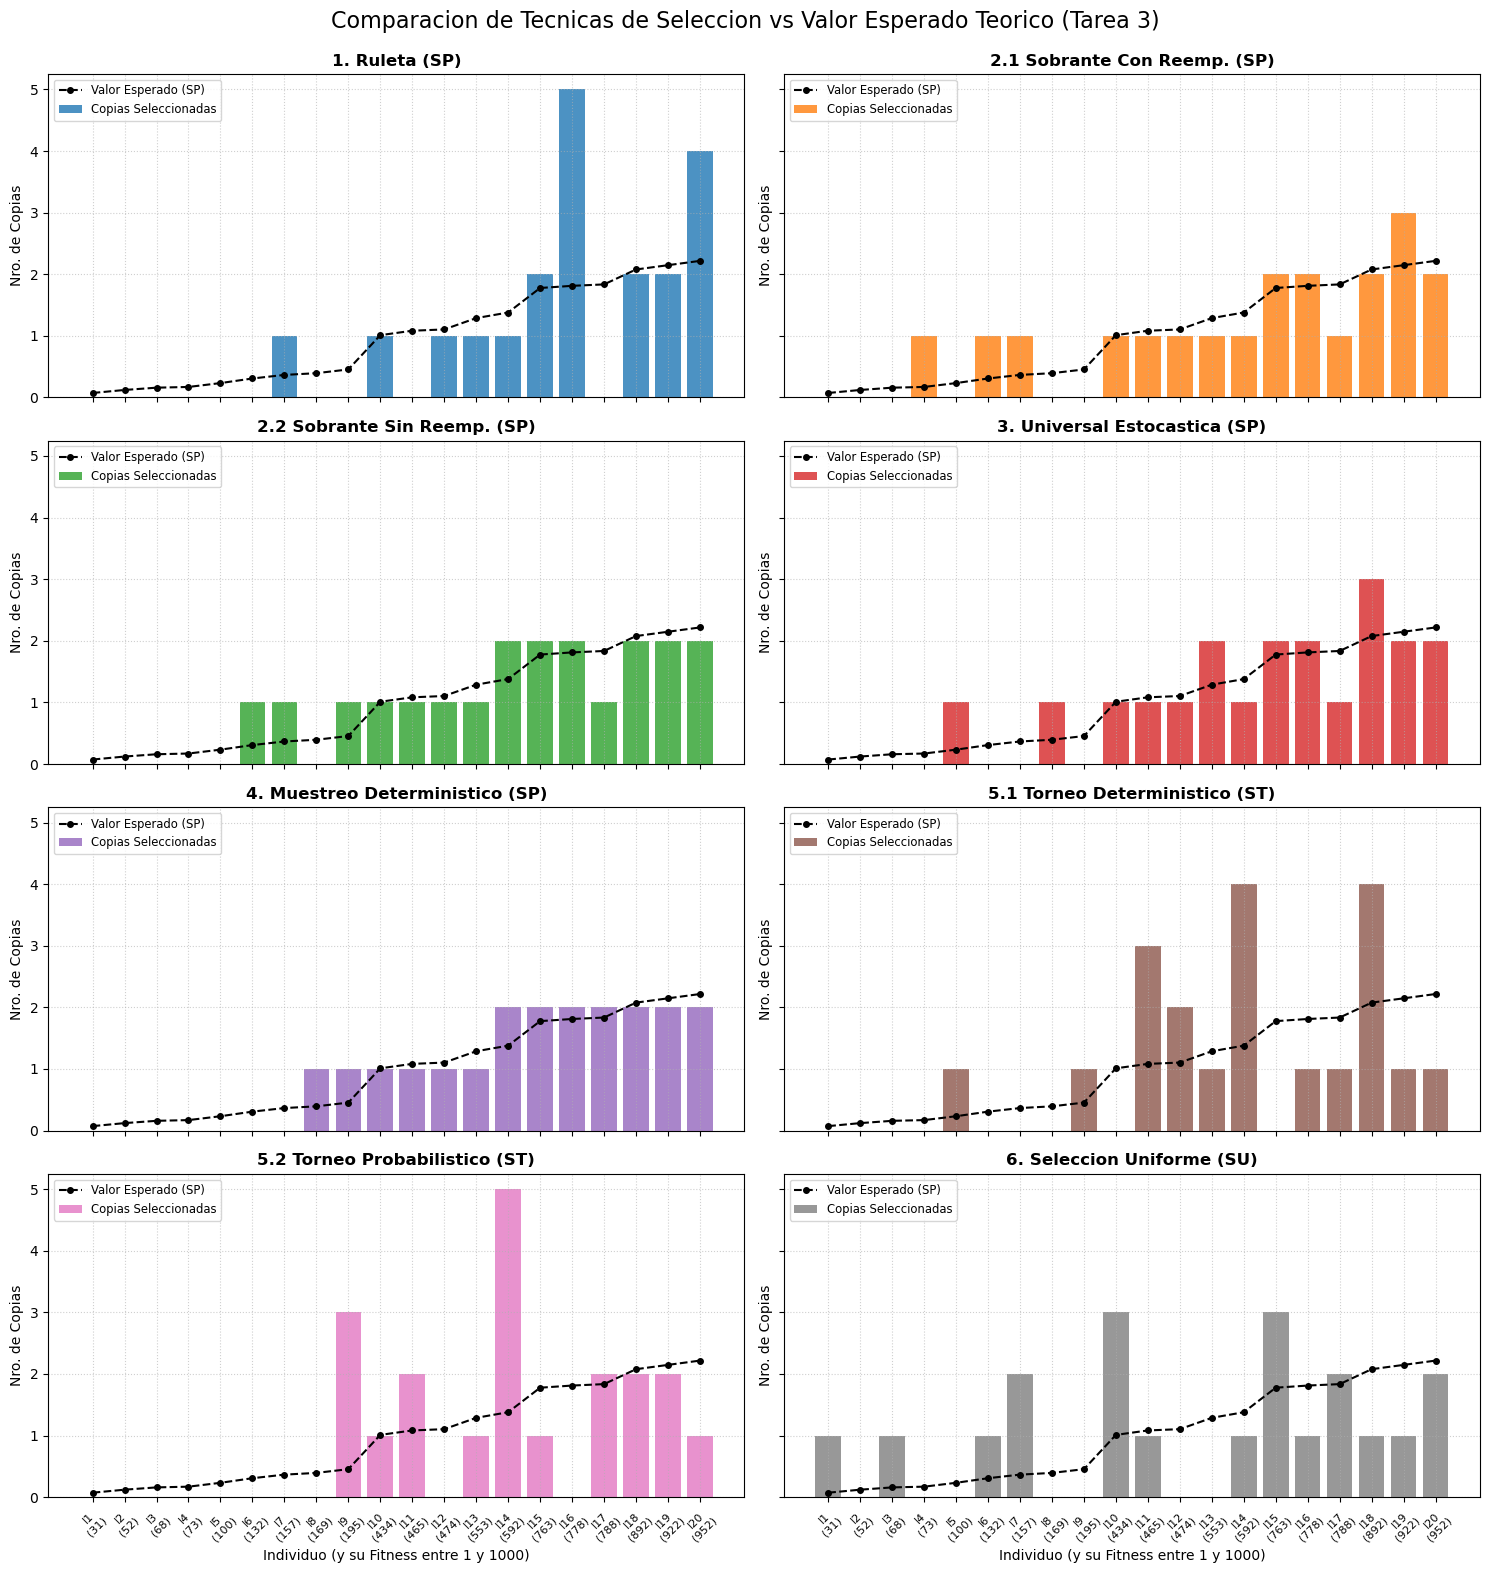

In [22]:
print("\n=====================================================================")
print("          TAREA 3: EVALUACION DE TECNICAS DE SELECCION               ")
print("=====================================================================\n")

# Parametros de prueba
N_POBLACION = 20  # Poblacion de 20 individuos para visualizar claramente tablas y graficas
K_TORNEO = 3      # Tamano de torneo
P_TORNEO = 0.75   # Probabilidad para torneo probabilistico

# 1. Inicializar poblacion con fitness entero entre 1 y 1000
poblacion_inicial, fitness_inicial = inicializar_poblacion_t3(N_POBLACION)

# Ordenamos la poblacion por fitness ascendente para que las graficas y tablas
# muestren claramente como las tecnicas favorecen a los individuos mas aptos
pares_ordenados = sorted(zip(fitness_inicial, poblacion_inicial), key=lambda x: x[0])
fitness_inicial = [f for f, _ in pares_ordenados]
poblacion_inicial = [ind for _, ind in pares_ordenados]

suma_fitness = sum(fitness_inicial)
valores_esperados = [(f / suma_fitness) * N_POBLACION for f in fitness_inicial]

# 2. Ejecutar todas las tecnicas de seleccion sobre la misma poblacion inicial
resultados_seleccion = {
    "1. Ruleta (SP)": seleccion_ruleta(poblacion_inicial, fitness_inicial)[1],
    "2.1 Sobrante Con Reemp. (SP)": seleccion_sobrante_con_reemplazo(poblacion_inicial, fitness_inicial)[1],
    "2.2 Sobrante Sin Reemp. (SP)": seleccion_sobrante_sin_reemplazo(poblacion_inicial, fitness_inicial)[1],
    "3. Universal Estocastica (SP)": seleccion_universal_estocastica(poblacion_inicial, fitness_inicial)[1],
    "4. Muestreo Deterministico (SP)": seleccion_muestreo_deterministico(poblacion_inicial, fitness_inicial)[1],
    "5.1 Torneo Deterministico (ST)": seleccion_torneo_deterministico(poblacion_inicial, fitness_inicial, k=K_TORNEO)[1],
    "5.2 Torneo Probabilistico (ST)": seleccion_torneo_probabilistico(poblacion_inicial, fitness_inicial, k=2, prob_mejor=P_TORNEO)[1],
    "6. Seleccion Uniforme (SU)": seleccion_uniforme(poblacion_inicial, fitness_inicial)[1]
}

# 3. Imprimir Tabla 1: Frecuencia de seleccion por individuo
print("TABLA 1: CONTEO DE SELECCIONES POR INDIVIDUO (N = 20)\n")
encabezado = (
    f"{'Ind':<4} | {'Fitness':<7} | {'Val.Esp(e_i)':<12} | "
    f"{'Ruleta':<6} | {'Sob.CR':<6} | {'Sob.SR':<6} | {'SUS':<5} | "
    f"{'M.Det':<5} | {'T.Det':<5} | {'T.Prob':<6} | {'Unif':<5}"
)
print(encabezado)
print("-" * len(encabezado))

for i in range(N_POBLACION):
    fila = (
        f"#{i+1:<3} | {fitness_inicial[i]:<7} | {valores_esperados[i]:<12.3f} | "
        f"{resultados_seleccion['1. Ruleta (SP)'][i]:<6} | "
        f"{resultados_seleccion['2.1 Sobrante Con Reemp. (SP)'][i]:<6} | "
        f"{resultados_seleccion['2.2 Sobrante Sin Reemp. (SP)'][i]:<6} | "
        f"{resultados_seleccion['3. Universal Estocastica (SP)'][i]:<5} | "
        f"{resultados_seleccion['4. Muestreo Deterministico (SP)'][i]:<5} | "
        f"{resultados_seleccion['5.1 Torneo Deterministico (ST)'][i]:<5} | "
        f"{resultados_seleccion['5.2 Torneo Probabilistico (ST)'][i]:<6} | "
        f"{resultados_seleccion['6. Seleccion Uniforme (SU)'][i]:<5}"
    )
    print(fila)

print("-" * len(encabezado))
print(f"Fitness Promedio de la Poblacion Inicial: {np.mean(fitness_inicial):.2f}\n")


# 4. Imprimir Tabla 2: Calidad promedio de los padres seleccionados por cada tecnica
print("TABLA 2: RESUMEN DE PRESION SELECTIVA POR TECNICA\n")
print(f"{'Tecnica de Seleccion':<34} | {'Fitness Promedio Padres':<24} | {'Max Copias de 1 Ind.'}")
print("-" * 82)

for nombre_tec, conteos in resultados_seleccion.items():
    # Calculamos el fitness promedio ponderado por el numero de veces que fue elegido cada padre
    fitness_padres = sum(f * c for f, c in zip(fitness_inicial, conteos)) / N_POBLACION
    max_copias = max(conteos)
    print(f"{nombre_tec:<34} | {fitness_padres:<24.2f} | {max_copias}")

print("-" * 82)


# 5. Visualizacion Grafica Comparativa (Estilo Tarea 2)
fig, axs = plt.subplots(4, 2, figsize=(15, 16), sharex=True, sharey=True)
fig.suptitle("Comparacion de Tecnicas de Seleccion vs Valor Esperado Teorico (Tarea 3)", fontsize=16)

indices_ind = np.arange(1, N_POBLACION + 1)
etiquetas_x = [f"I{i}\n({f})" for i, f in zip(indices_ind, fitness_inicial)]

colores = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f']

for idx, (nombre_tec, conteos) in enumerate(resultados_seleccion.items()):
    fila = idx // 2
    col = idx % 2
    ax = axs[fila, col]

    # Barras con el numero de selecciones reales
    ax.bar(indices_ind, conteos, color=colores[idx], alpha=0.8, label="Copias Seleccionadas")
    # Linea punteada con el valor esperado proporcional (e_i)
    ax.plot(indices_ind, valores_esperados, color='black', linestyle='--', marker='o', markersize=4, label="Valor Esperado (SP)")

    ax.set_title(nombre_tec, fontsize=12, fontweight='bold')
    ax.set_ylabel("Nro. de Copias")
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc="upper left", fontsize="small")

    if fila == 3:
        ax.set_xticks(indices_ind)
        ax.set_xticklabels(etiquetas_x, rotation=45, fontsize=8)
        ax.set_xlabel("Individuo (y su Fitness entre 1 y 1000)")

plt.tight_layout()
plt.subplots_adjust(top=0.94)
plt.show()

¿Qué observarás al ejecutar este código para tu análisis de resultados?
Precisión en Selección Proporcional (SP):
En la Tabla 1 y en los gráficos verás cómo la Ruleta (1) presenta alta varianza estocástica (algunos individuos con alto fitness pueden recibir 0 copias por azar y otros recibir demasiadas).
En cambio, Sobrante Estocástico (2.1 y 2.2), Universal Estocástica - SUS (3) y Muestreo Determinístico (4) siguen fielmente la curva negra punteada del Valor Esperado (
e
i
e 
i
​
 
), garantizando que todo individuo con 
e
i
≥
1
e 
i
​
 ≥1
 reciba al menos su parte entera de copias (cero sesgo y mínima dispersión).
Presión Selectiva en Torneo (ST):
En la Tabla 2, observarás que el Torneo Determinístico (
k
=
3
k=3
) genera el mayor fitness promedio en la población de padres, ya que descarta sistemáticamente a los individuos con fitness bajo y concentra las copias en la élite superior.
El Torneo Probabilístico suaviza esta presión selectiva al permitir que, con probabilidad 
1
−
p
1−p
, sobrevivan individuos de menor adaptación.
Selección Uniforme (SU):
Funciona como línea base de control sin presión selectiva: el fitness promedio de los padres seleccionados se mantiene cercano al promedio original de la población inicial, repartiendo copias al azar sin importar si el individuo tiene un fitness de 10 o de 990.